# Ten-minute League of Legends win prediction

Group 27 progress-report experiment walkthrough. All scores below are **validation** results; the final test set stays reserved.

The question is whether objectives and vision add predictive information beyond economy, experience, farming and combat. We first establish simple baselines, then hold the model and split constant while changing the input features.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

root = Path.cwd()
if not (root / 'code' / 'run_experiments.py').exists():
    root = root / 'progress-report'
assert (root / 'code' / 'run_experiments.py').exists(), 'Open from the project or progress-report folder.'
sys.path.insert(0, str(root / 'code'))
from run_experiments import (load_data, feature_frame, saved_splits, CORE, OBJECTIVES,
                             VISION, EXPERIMENTS, run, metrics)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
results = root / 'results'
results.mkdir(exist_ok=True)

## 1. Check the dataset

Each row is one match. The final winner is the label, and the other fields describe the published ten-minute checkpoint. `gameId` tracks rows and is excluded from model inputs. We check duplicates, missing cells and exact arithmetic relationships. We retain all rows; unusually high ward counts remain a documented quality concern.

In [2]:
data, audit = load_data(root / 'data' / 'high_diamond_ranked_10min.csv')
display(pd.Series({k: audit[k] for k in ['rows', 'columns', 'source_predictors', 'missing_cells', 'duplicate_ids']}))
display(data['blueWins'].value_counts().sort_index().rename_axis('blueWins').to_frame('matches'))

rows                 9879
columns                40
source_predictors      38
missing_cells           0
duplicate_ids           0
dtype: int64

,matches
blueWins,
0,4949
1,4930


## 2. Construct differences

For each quantity, calculate blue minus red. A positive gold difference means blue has more gold. The seven core inputs are gold, XP, average level, lane CS, jungle CS, kills and assists. Deaths would duplicate the opposing kill count; fixed-time gold/CS rates duplicate totals. Separate objective and vision additions let us distinguish their contributions. No outcome-based feature selection is performed.

In [3]:
features = feature_frame(data)
display(pd.Series({name: ', '.join(columns) for name, columns in EXPERIMENTS.items()}, name='inputs'))
display(features.head())

gold_only                                                              gold
core                      gold, experience, level, lane_cs, jungle_cs, k...
core_objectives           gold, experience, level, lane_cs, jungle_cs, k...
core_vision               gold, experience, level, lane_cs, jungle_cs, k...
core_objectives_vision    gold, experience, level, lane_cs, jungle_cs, k...
Name: inputs, dtype: object

,gold,experience,level,lane_cs,jungle_cs,kills,assists,dragons,heralds,wards_placed,wards_destroyed
0,643,-8,-0.2,-2,-19,3,3,0,0,13,-4
1,-2908,-1173,-0.2,-66,-9,0,3,-1,-1,0,0
2,-1172,-1033,-0.4,-17,18,-4,-10,1,0,0,-3
3,-1321,-7,0.0,-34,8,-1,-5,0,1,28,-1
4,-1004,230,0.0,-15,-10,0,-1,-1,0,58,2


## 3. Reserve the final test set

We use a stratified 70/15/15 split with seed 42, preserving nearly equal class proportions. Saved match IDs are reused on every run. Random splitting is appropriate for the fields available; missing dates prevent verified chronological evaluation, and missing player IDs prevent checking overlap between players. We do not calculate test performance.

In [4]:
indices, allocation = saved_splits(data, results)
display(pd.DataFrame(allocation).T)
train_idx, validation_idx = indices['train'], indices['validation']
X_train = features.iloc[train_idx]
X_validation = features.iloc[validation_idx]
y_train = data['blueWins'].iloc[train_idx].to_numpy()
y_validation = data['blueWins'].iloc[validation_idx].to_numpy()

,n,blue_wins,red_wins
train,6915,3451,3464
validation,1482,740,742
test,1482,739,743


## 4. Fit the core model

Logistic regression maps a weighted sum of the inputs to a probability through a sigmoid. It minimizes binary cross-entropy with L2 regularization. We use scikit-learn's L-BFGS solver, not a custom SGD loop. `C=1`, tolerance `1e-6`, maximum 2,000 iterations and the 0.5 classification threshold are fixed.

The pipeline fits means and scales using **training rows only**, then applies that same transformation to validation rows. This avoids letting held-out statistics influence the fit.

In [5]:
core_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, penalty='l2', solver='lbfgs', max_iter=2000,
                       tol=1e-6, random_state=42)
)
core_model.fit(X_train[CORE], y_train)
core_probability = core_model.predict_proba(X_validation[CORE])[:, 1]
core_prediction = (core_probability >= 0.5).astype(int)
display(pd.Series(metrics(y_validation, core_prediction, core_probability)))
print('Optimizer iterations:', core_model.named_steps['logisticregression'].n_iter_[0])

accuracy          0.719298
precision_blue    0.712598
recall_blue       0.733784
f1_blue           0.723036
roc_auc           0.798457
brier             0.183621
log_loss          0.543314
dtype: float64

Optimizer iterations: 21


## 5. Reproduce every comparison

The majority baseline predicts red for every validation match because red is slightly more common in training. Its blue-class precision/recall/F1 are zero under our stated convention. A separate constant-probability baseline uses the training blue-win rate, allowing meaningful Brier/log-loss comparison. We do not substitute extreme 0/1 probabilities from the majority baseline.

The script fits all five logistic feature sets and saves full metrics, predictions, coefficients, diagnostics and figures. No hyperparameter search or calibration is performed. Different feature sets are exploratory comparisons rather than evidence of a final selected model.

In [6]:
run(root / 'data' / 'high_diamond_ranked_10min.csv', results)
table = pd.read_csv(results / 'validation_metrics.csv')
display(table.round(6))

                 model  n_features  accuracy  precision_blue  recall_blue  f1_blue  roc_auc    brier  log_loss
              majority           0  0.500675        0.000000     0.000000 0.000000      NaN      NaN       NaN
  constant_probability           0  0.500675        0.000000     0.000000 0.000000 0.500000 0.250000  0.693146
             gold_only           1  0.710526        0.704336     0.724324 0.714191 0.792625 0.186106  0.549583
                  core           7  0.719298        0.712598     0.733784 0.723036 0.798457 0.183621  0.543314
       core_objectives           9  0.722672        0.712258     0.745946 0.728713 0.800555 0.182759  0.539686
           core_vision           9  0.719298        0.712598     0.733784 0.723036 0.798417 0.183641  0.543365
core_objectives_vision          11  0.721323        0.710968     0.744595 0.727393 0.800379 0.182846  0.539899

Split sizes: {'train': 6915, 'validation': 1482, 'test': 1482}
Test set evaluated: NO
Saved results: C:\Code\4a

,model,n_features,accuracy,precision_blue,recall_blue,f1_blue,roc_auc,brier,log_loss
0,majority,0,0.500675,0.000000,0.000000,0.000000,NaN,NaN,NaN
1,constant_probability,0,0.500675,0.000000,0.000000,0.000000,0.500000,0.250000,0.693146
2,gold_only,1,0.710526,0.704336,0.724324,0.714191,0.792625,0.186106,0.549583
3,core,7,0.719298,0.712598,0.733784,0.723036,0.798457,0.183621,0.543314
4,core_objectives,9,0.722672,0.712258,0.745946,0.728713,0.800555,0.182759,0.539686
5,core_vision,9,0.719298,0.712598,0.733784,0.723036,0.798417,0.183641,0.543365
6,core_objectives_vision,11,0.721323,0.710968,0.744595,0.727393,0.800379,0.182846,0.539899


## 6. Interpret probabilities and uncertainty

Brier score is mean squared probability error; log loss penalizes confidently incorrect predictions. Lower is better for both. ROC-AUC measures ranking, and accuracy evaluates a 0.5 threshold; these answer different questions.

The reliability diagram compares average predicted probability with the actual blue-win frequency in ten equal-width bins. The diagonal represents agreement. It is a descriptive check, not proof of calibration.

We bootstrap paired validation rows 2,000 times to compare the expanded model with the core model. This interval is conditional on the already fitted models. It does not cover model-training variability, player dependence, repeated split selection, or multiple comparisons.

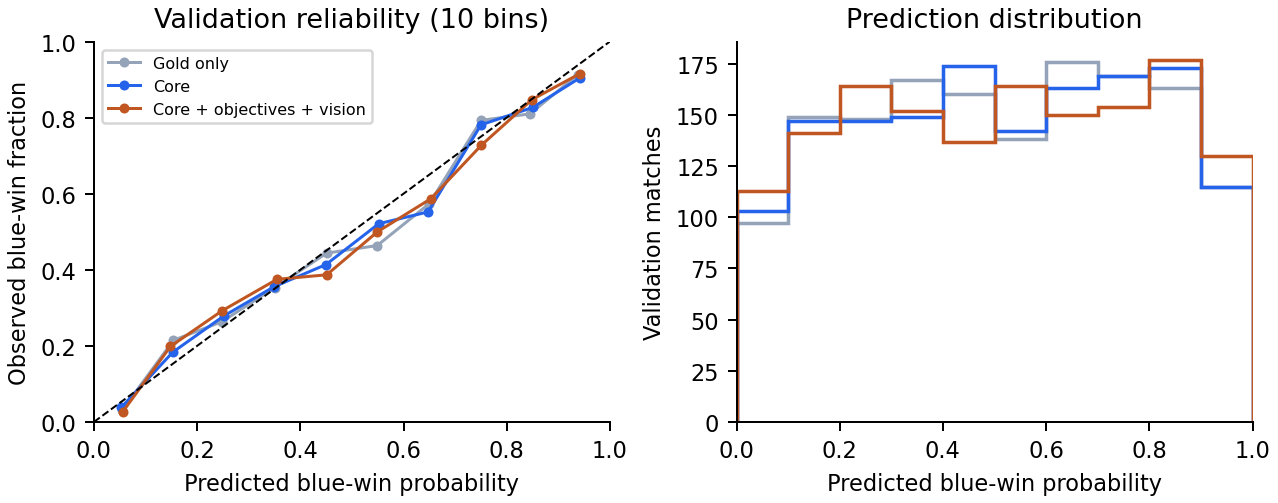

,estimate,lower_95,upper_95
accuracy,0.002024,-0.012146,0.016869
brier,-0.000775,-0.003394,0.001876
log_loss,-0.003416,-0.009797,0.002912


In [7]:
display(Image(filename=str(results / 'figures' / 'calibration.png')))
comparison = json.loads((results / 'paired_validation_comparison.json').read_text())
display(pd.DataFrame(comparison['differences']).T)

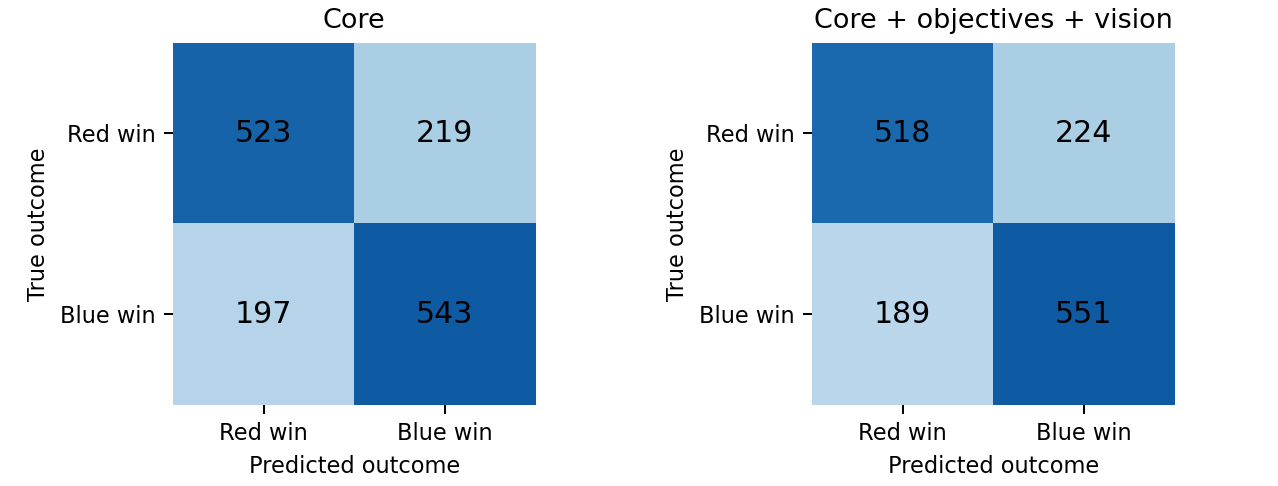

The test set remains reserved.


In [8]:
display(Image(filename=str(results / 'figures' / 'confusion_matrices.png')))
config = json.loads((results / 'experiment_config.json').read_text())
assert config['test_evaluated'] is False
print('The test set remains reserved.')

## 7. What this run establishes

The learned models clearly exceed the majority baseline on this validation split. Gold alone captures much of the available signal. Objectives yield a small preliminary improvement, while these two vision differences add little in this linear model. The expanded-versus-core bootstrap intervals include zero, so the result is not strong evidence of a reliable gain.

Next work can compare nonlinear models, assess calibration and feature robustness with training-only cross-validation, and inspect unusual ward values. The original data omit player identity, patch, dates and region. Predictive associations are not causal effects, and these results do not establish performance on current League patches. Individual human contributions and AI-use disclosure must be confirmed before submission.

## 8. Compare random forests with logistic regression

We now test a nonlinear model using the same saved train/validation matches. The forest uses 500 bootstrap trees, maximum depth 8, minimum 10 samples per leaf, square-root feature subsampling, Gini splits and seed 42. These settings were fixed before inspecting the forest scores. Trees use raw feature differences, without scaling. This is an initial comparison, not a tuned optimum. The test set stays reserved.

                 model  n_features  accuracy  precision_blue  recall_blue  f1_blue  roc_auc    brier  log_loss
                  core           7  0.719298        0.712598     0.733784 0.723036 0.798457 0.183621  0.543314
core_objectives_vision          11  0.721323        0.710968     0.744595 0.727393 0.800379 0.182846  0.539899
           forest_core           7  0.717949        0.704835     0.748649 0.726081 0.796472 0.184371  0.545712
       forest_expanded          11  0.718623        0.707317     0.744595 0.725477 0.800373 0.182783  0.540116

Fixed forest configuration: {'n_estimators': 500, 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 10, 'min_samples_split': 2, 'max_features': 'sqrt', 'bootstrap': True, 'random_state': 42, 'n_jobs': -1, 'class_weight': None}
Test set evaluated: NO


,model,n_features,accuracy,precision_blue,recall_blue,f1_blue,roc_auc,brier,log_loss
0,core,7,0.719298,0.712598,0.733784,0.723036,0.798457,0.183621,0.543314
1,core_objectives_vision,11,0.721323,0.710968,0.744595,0.727393,0.800379,0.182846,0.539899
2,forest_core,7,0.717949,0.704835,0.748649,0.726081,0.796472,0.184371,0.545712
3,forest_expanded,11,0.718623,0.707317,0.744595,0.725477,0.800373,0.182783,0.540116


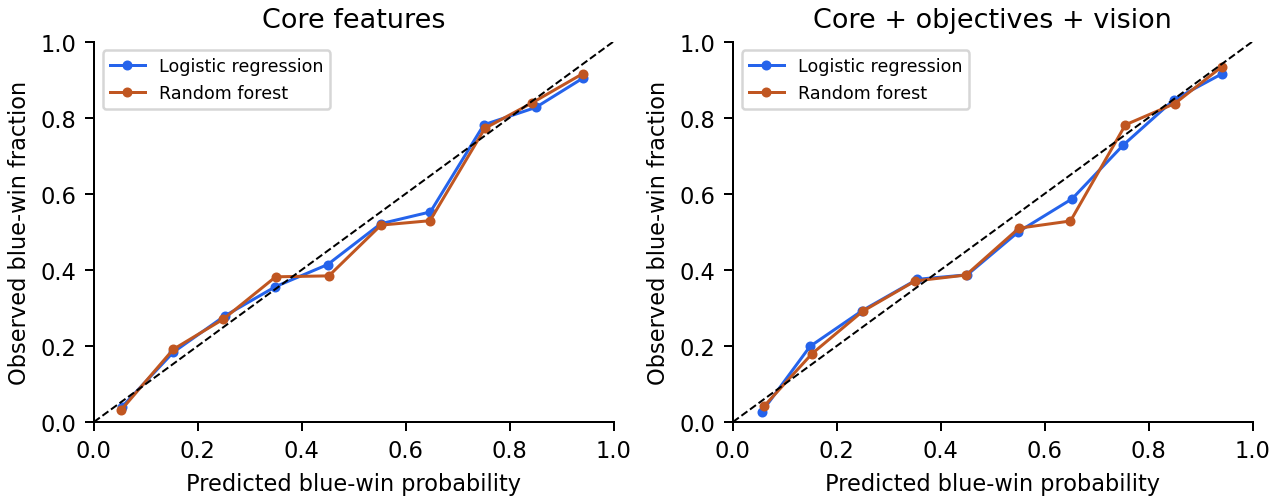

In [9]:
from run_random_forest import run as run_forests
run_forests(root)
display(pd.read_csv(results / 'model_family_comparison.csv').round(6))
display(Image(filename=str(results / 'figures' / 'model_family_calibration.png')))

## 9. Results to discuss with the TA/team

The core forest achieves 71.79% validation accuracy versus 71.93% for matched logistic regression; the expanded forest achieves 71.86% versus 72.13%. Paired model-family intervals include zero, so this run gives no clear winner. Expanded features improve the forest's probability error while barely changing accuracy. The conditional log-loss improvement interval excludes zero, but is exploratory and does not account for training/split variability, player dependence or multiple comparisons.

The next decision is whether to strengthen validation/tuning or change data scope after TA/team feedback. See MODEL_COMPARISON.md for settings, uncertainty and discussion questions. The report PDF remains the earlier logistic-only draft.

In [10]:
from verify_results import verify
verify(root)

PASS: dataset identity; disjoint saved split; validation-only predictions; training-only scaler;
      independent sigmoid reconstruction; reported accuracy, Brier and log loss; baseline values.
PASS: forest shares the original split/validation rows; reported metrics recompute;
      combined results preserve all original logistic scores; no test predictions present.
